# PHẦN 1 — Bài 2 (Trang 30): Tiền xử lý và Trực quan hóa dữ liệu cảm biến (`tb_tracking.xlsx`)

- **Sinh viên thực hiện**: Dương Đại Phát – MSSV: `6451071058` – Lớp: `CQ.64.CNTT`
- **Nguồn dữ liệu**: `tb_tracking.xlsx` (Google Drive Folder: https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing, File ID: `1Xizh3zvtMF4IdRNlueb74meOXk80-CHc`)
- **Mục tiêu**: Thực hiện đầy đủ 4 yêu cầu **a, b, c, d** (PDF trang 30).

## Khởi tạo môi trường và tải dữ liệu (Colab-ready)

In [1]:
print("Dương Đại Phát - 6451071058")
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

DATA_FILE = "tb_tracking.xlsx"
DRIVE_ID = "1Xizh3zvtMF4IdRNlueb74meOXk80-CHc"

if os.path.exists(os.path.join("datasets", DATA_FILE)):
    DATA_PATH = os.path.join("datasets", DATA_FILE)
elif os.path.exists(DATA_FILE):
    DATA_PATH = DATA_FILE
else:
    try:
        import gdown
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown", "openpyxl"])
        import gdown
    gdown.download(f"https://drive.google.com/uc?id={DRIVE_ID}", DATA_FILE, quiet=False)
    DATA_PATH = DATA_FILE

print("Đường dẫn dữ liệu:", DATA_PATH)

Dương Đại Phát - 6451071058


Đường dẫn dữ liệu: datasets\tb_tracking.xlsx


## Câu a: Thêm tiêu đề các cột theo thứ tự (`id`, `device_id`, `co_level`, `humidity`, `temperature`, `time`)

**Lưu ý quan trọng về cấu trúc tệp `tb_tracking.xlsx`:**
- Sheet `tb_tracking` không có dòng tiêu đề (`header=None`).
- Các dòng **1 đến 33.336** là dữ liệu đo thực tế từ cảm biến.
- Dòng **33.337** là dòng trống và các dòng **33.338–33.340** là các dòng công thức thống kê Excel (`MIN`, `MAX`, `AVERAGE`). Do đó cần đọc đúng `nrows=33336` để loại bỏ hoàn toàn các dòng tổng hợp cuối bảng.

In [2]:
print("Dương Đại Phát - 6451071058")
col_names = ["id", "device_id", "co_level", "humidity", "temperature", "time"]
df = pd.read_excel(
    DATA_PATH,
    header=None,
    nrows=33336,
    names=col_names,
    engine="openpyxl",
)

print(f"Kích thước dữ liệu đọc vào: {df.shape[0]} dòng x {df.shape[1]} cột")
display(df.head(10))
display(df.tail(5))
print("\n=== THÔNG TIN CẤU TRÚC (df.info) ===")
df.info()

Dương Đại Phát - 6451071058


Kích thước dữ liệu đọc vào: 33336 dòng x 6 cột


,id,device_id,co_level,humidity,temperature,time
0,1,1,2.0,3,4,2016-12-20 12:52:29
1,2,1,2.0,3,4,2016-12-20 12:52:31
2,3,100,2.0,3,4,2016-12-20 12:52:35
3,4,100,2.0,3,400,2016-12-20 12:52:37
4,5,1,2.0,3,4,2016-12-20 13:02:01
5,6,100,2.0,3,400,2016-12-20 13:02:24
6,7,-1,0.0,83,28,2016-12-21 12:03:39
7,8,-1,0.0,83,28,2016-12-21 12:05:02
8,9,-1,0.0,83,28,2016-12-21 12:05:49
9,10,1,2.0,3,4,2016-12-21 12:08:58


,id,device_id,co_level,humidity,temperature,time
33331,33332,0,32.0,58,2049770,2018-01-17 15:26:12
33332,33333,0,32.0,58,1983470,2018-01-17 15:31:18
33333,33334,0,32.0,59,2119740,2018-01-17 15:36:24
33334,33335,0,32.0,61,2096030,2018-01-17 15:41:29
33335,33336,0,31.5,62,2004240,2018-01-17 15:46:34



=== THÔNG TIN CẤU TRÚC (df.info) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33336 entries, 0 to 33335
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           33336 non-null  int64         
 1   device_id    33336 non-null  int64         
 2   co_level     33336 non-null  float64       
 3   humidity     33336 non-null  int64         
 4   temperature  33336 non-null  int64         
 5   time         33336 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(4)
memory usage: 1.5 MB


## Câu b: Loại bỏ các dữ liệu trước ngày `03/01/2018` (`2018-01-03`)

In [3]:
print("Dương Đại Phát - 6451071058")
df["time"] = pd.to_datetime(df["time"])
print("Khoảng thời gian ban đầu:", df["time"].min(), "->", df["time"].max())

df_valid = df[df["time"] >= "2018-01-03"].copy().reset_index(drop=True)
removed_count = len(df) - len(df_valid)

print(f"Số dòng bị loại bỏ (trước 03/01/2018): {removed_count}")
print(f"Số dòng hợp lệ còn lại (từ 03/01/2018): {len(df_valid)}")
print("Khoảng thời gian sau khi lọc:", df_valid["time"].min(), "->", df_valid["time"].max())
print("\nSố giá trị rỗng trong dữ liệu hợp lệ:")
display(df_valid.isnull().sum())
display(df_valid.describe())

Dương Đại Phát - 6451071058
Khoảng thời gian ban đầu: 2016-12-20 12:52:29 -> 2018-01-17 15:46:34
Số dòng bị loại bỏ (trước 03/01/2018): 31419
Số dòng hợp lệ còn lại (từ 03/01/2018): 1917
Khoảng thời gian sau khi lọc: 2018-01-03 13:11:07 -> 2018-01-17 15:46:34

Số giá trị rỗng trong dữ liệu hợp lệ:


id             0
device_id      0
co_level       0
humidity       0
temperature    0
time           0
dtype: int64

,id,device_id,co_level,humidity,temperature,time
count,1917.000000,1917.000000,1917.000000,1917.000000,1.917000e+03,1917
mean,32378.000000,88985.715702,28.190662,68.992697,2.358965e+06,2018-01-08 20:01:03.683880960
min,31420.000000,0.000000,2.000000,3.000000,0.000000e+00,2018-01-03 13:11:07
25%,31899.000000,99005.000000,27.000000,61.000000,2.124650e+06,2018-01-05 11:46:41
50%,32378.000000,99005.000000,28.000000,70.000000,2.331120e+06,2018-01-09 00:38:28
75%,32857.000000,99005.000000,28.000000,79.000000,2.570550e+06,2018-01-11 11:52:31
max,33336.000000,99005.000000,77.000000,86.000000,5.340310e+06,2018-01-17 15:46:34
std,553.534552,29867.012091,3.997557,12.033094,4.951416e+05,NaN


**Nhận xét (Câu b):**
- Dữ liệu gốc có 33.336 dòng từ `2016-12-20` đến `2018-01-17`.
- Sau khi loại bỏ **31.419** dòng đo trước ngày hiệu chỉnh cảm biến `2018-01-03`, tập dữ liệu sạch còn lại đúng **1.917 dòng** hợp lệ (từ `2018-01-03 13:11:07` đến `2018-01-17 15:46:34`), không có giá trị `NaN`.

## Câu c: Bóc tách từ cột `time` thành thời điểm đo đạc trong ngày tính theo phút (`minutes`)

Công thức quy đổi thời điểm trong ngày (`00:00:00` – `23:59:59`) sang phút trong khoảng `[0, 1440)`:
$$\text{minutes} = \text{hour} \times 60 + \text{minute} + \frac{\text{second}}{60}$$

In [4]:
print("Dương Đại Phát - 6451071058")
df_valid["minutes"] = (
    df_valid["time"].dt.hour * 60
    + df_valid["time"].dt.minute
    + df_valid["time"].dt.second / 60.0
).round(2)

display(df_valid[["id", "device_id", "co_level", "humidity", "temperature", "time", "minutes"]].head(10))
print("\nThống kê mô tả cột minutes:")
display(df_valid["minutes"].describe().round(2))

Dương Đại Phát - 6451071058


,id,device_id,co_level,humidity,temperature,time,minutes
0,31420,1,2.0,3,4,2018-01-03 13:11:07,791.12
1,31421,1,2.0,3,4,2018-01-03 13:15:10,795.17
2,31422,99005,58.0,26,0,2018-01-03 13:17:30,797.50
3,31423,99005,58.0,26,0,2018-01-03 13:19:21,799.35
4,31424,99005,58.0,26,0,2018-01-03 13:24:17,804.28
5,31425,99005,60.0,26,0,2018-01-03 13:29:13,809.22
6,31426,99005,64.0,26,0,2018-01-03 13:34:10,814.17
7,31427,99005,60.0,27,0,2018-01-03 14:05:34,845.57
8,31428,99005,60.0,27,0,2018-01-03 14:10:43,850.72
9,31429,99005,60.0,27,0,2018-01-03 14:15:39,855.65



Thống kê mô tả cột minutes:


count    1917.00
mean      709.79
std       391.94
min         1.50
25%       396.18
50%       713.48
75%       993.42
max      1439.00
Name: minutes, dtype: float64

## Câu d: Vẽ đồ thị phân tán (scatter-plots) của `co_level`, `humidity` và `temperature` theo `minutes`

Dương Đại Phát - 6451071058


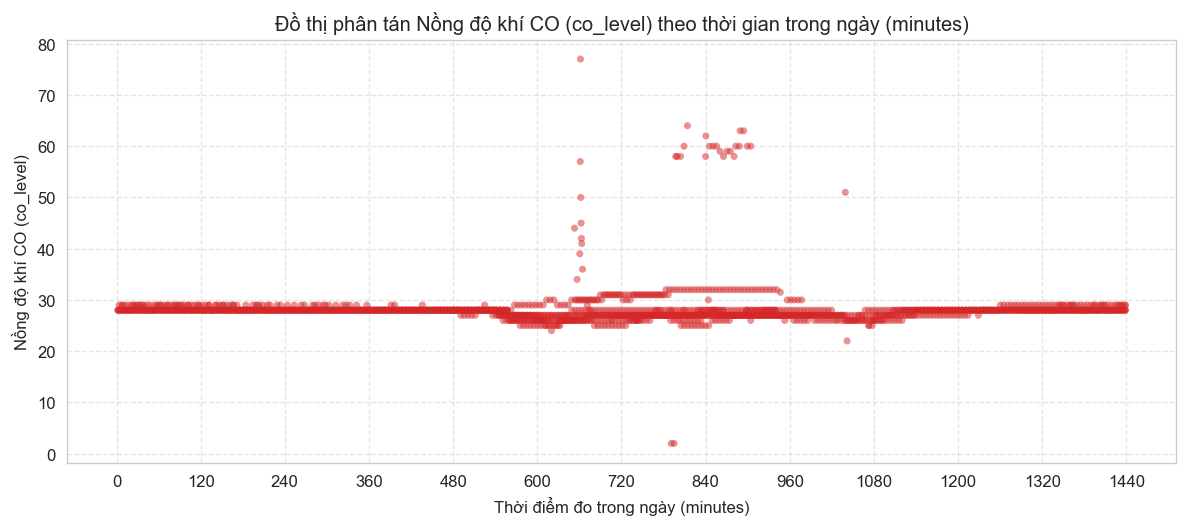

In [5]:
print("Dương Đại Phát - 6451071058")
xticks_2h = list(range(0, 1441, 120))

# 1. Scatter plot Nồng độ khí CO (co_level) theo minutes
plt.figure(figsize=(10, 4.5))
plt.scatter(df_valid["minutes"], df_valid["co_level"], alpha=0.5, s=18, color="tab:red", edgecolors="none")
plt.title("Đồ thị phân tán Nồng độ khí CO (co_level) theo thời gian trong ngày (minutes)")
plt.xlabel("Thời điểm đo trong ngày (minutes)")
plt.ylabel("Nồng độ khí CO (co_level)")
plt.xticks(xticks_2h)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Dương Đại Phát - 6451071058


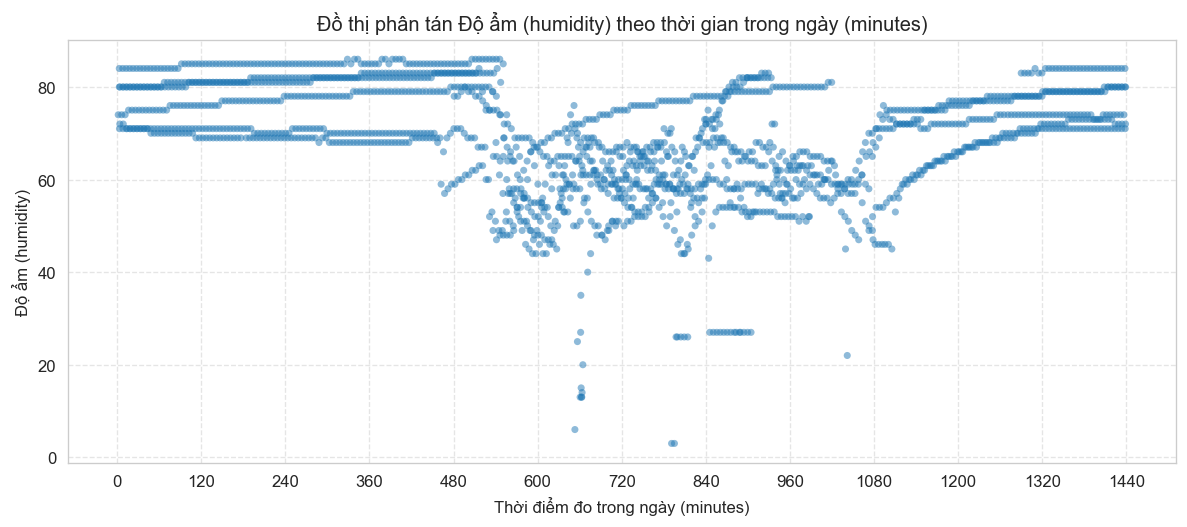

In [6]:
print("Dương Đại Phát - 6451071058")
# 2. Scatter plot Độ ẩm (humidity) theo minutes
plt.figure(figsize=(10, 4.5))
plt.scatter(df_valid["minutes"], df_valid["humidity"], alpha=0.5, s=18, color="tab:blue", edgecolors="none")
plt.title("Đồ thị phân tán Độ ẩm (humidity) theo thời gian trong ngày (minutes)")
plt.xlabel("Thời điểm đo trong ngày (minutes)")
plt.ylabel("Độ ẩm (humidity)")
plt.xticks(xticks_2h)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Dương Đại Phát - 6451071058


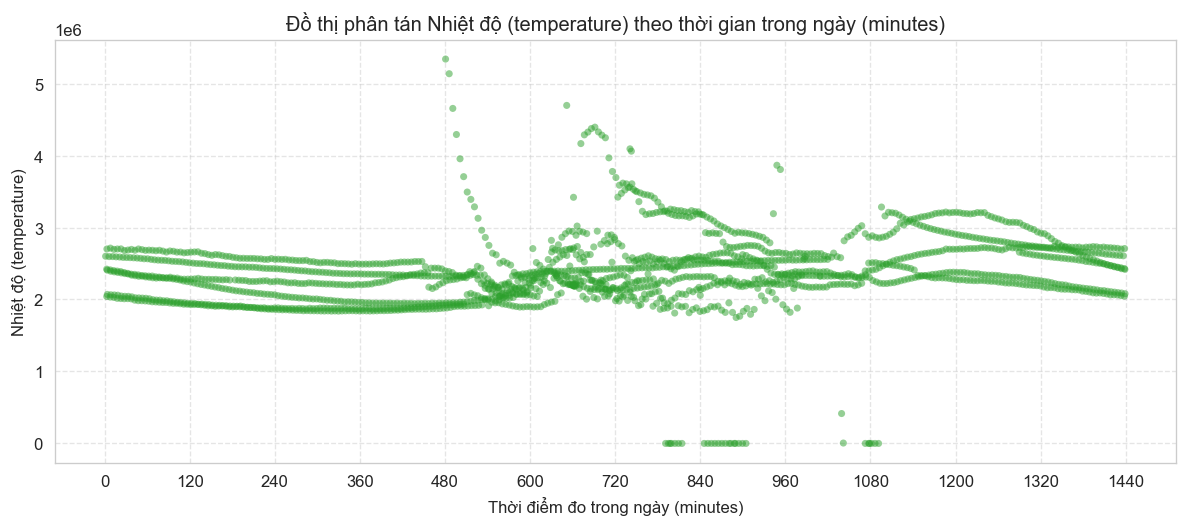

Số lượng bản ghi có giá trị bằng 0:


co_level        0
humidity        0
temperature    22
dtype: int64

In [7]:
print("Dương Đại Phát - 6451071058")
# 3. Scatter plot Nhiệt độ (temperature) theo minutes
plt.figure(figsize=(10, 4.5))
plt.scatter(df_valid["minutes"], df_valid["temperature"], alpha=0.5, s=18, color="tab:green", edgecolors="none")
plt.title("Đồ thị phân tán Nhiệt độ (temperature) theo thời gian trong ngày (minutes)")
plt.xlabel("Thời điểm đo trong ngày (minutes)")
plt.ylabel("Nhiệt độ (temperature)")
plt.xticks(xticks_2h)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Số lượng bản ghi có giá trị bằng 0:")
display((df_valid[["co_level", "humidity", "temperature"]] == 0).sum())

**Nhận xét tổng hợp (Câu d):**
- **`co_level`**: Phần lớn các điểm đo tập trung ổn định quanh mức **27–28** (Q1 = `27`, median = `28`, Q3 = `28`), xuất hiện một số điểm ngoại lai giảm xuống tới `2` hoặc tăng đột biến lên tới `77` (chủ yếu trong khoảng `480–1080` phút tức 8h–18h).
- **`humidity`**: Dao động chủ yếu từ **50 đến 86** (trung vị `70`, trung bình `68,99`), có xu hướng cao hơn vào ban đêm/sáng sớm (`0–400` phút) và giảm dần vào buổi trưa/chiều (`600–960` phút), kèm một vài giá trị thấp bất thường xuống `3`.
- **`temperature`**: Giá trị thô của cảm biến nằm chủ yếu trong khoảng **1,8×10⁶ đến 3,1×10⁶** (trung vị `2.331.120` ≈ `23,31°C` nếu chia $10^5$), đồng thời ghi nhận **22 điểm có giá trị bằng `0`** (nhiễu cảm biến) và một số điểm tăng cao tới `5.340.310`.